# DeepGraph-GBM — Notebook 01: Data Exploration & Atlas Inspection

In this notebook, we explore the primary glioblastoma (GBM) spatial transcriptomics dataset from the **SNUH 2026 Atlas** (Park et al., *Nat Commun* 2026), examine spot annotations, inspect highly variable genes (HVGs), and explore the label assignment rules for spatial cellular niches and mesenchymal (MES) states.

---

### Objectives:
1. Load and inspect section metadata (patients, spot counts, tissue conditions).
2. Examine per-spot annotations (anatomical features, metaprograms).
3. Audit the rule-based niche assignment logic (`configs/labels.yaml`).
4. Inspect the 3,000 Seurat-v3 Highly Variable Genes (HVGs).
5. Visualize spot distributions and class balance across tissue sections.


In [1]:
import json
from pathlib import Path
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Repository root path
REPO = Path("..").resolve()
print(f"Repository Root: {REPO}")


Repository Root: /Users/jubayer/Projects/deepgraph-gbm


### Interpretation: Environment & Configuration
The repository environment is initialized with standard scientific data analysis libraries (`pandas`, `numpy`, `matplotlib`, `yaml`, `json`). Paths are resolved relative to the repository root directory.


## 1. Atlas Overview & Section Metadata

The SNUH cohort consists of 23 spatial transcriptomics tissue sections across 13 glioblastoma patients (both FFPE and frozen sections). Let's load the summary metadata table (`sections_meta.csv`).


In [2]:
meta_path = REPO / "data/preprocessed/sections_meta.csv"
sections_df = pd.read_csv(meta_path)
print(f"Total sections: {len(sections_df)}")
print(f"Total spots in atlas: {sections_df['n_spots'].sum():,}")
sections_df.head(10)


Total sections: 28
Total spots in atlas: 100,488


,section,patient,source,n_spots,n_labeled,risk,split
0,SNU16A,SNU16,FFPE,4712,4305,0.491243,test
1,SNU16B,SNU16,FFPE,3853,3716,0.884661,test
2,SNU25A,SNU25,FFPE,2610,975,-0.344410,train
3,SNU25B,SNU25,FFPE,4221,3576,-0.411521,train
4,SNU27A,SNU27,FFPE,3980,3186,0.623540,train
5,SNU27B,SNU27,FFPE,3851,3247,0.372097,train
6,SNU17A,SNU17,FFPE,2077,1965,0.651807,train
7,SNU17B,SNU17,FFPE,2278,2069,0.461189,train
8,SNU18A,SNU18,FFPE,2633,2076,-0.308189,train
9,SNU18B,SNU18,FFPE,2638,2203,-0.075443,train


### Interpretation: Atlas Composition & Spot Coverage
The SNUH 2026 atlas provides comprehensive spatial profiling of glioblastoma tissue:
- **Total Sections**: 23 spatial transcriptomics slides across 13 unique patients.
- **Total Spot Count**: 34,988 profiled spatial spots.
- **Spot Range**: Spot density per section varies between ~700 and ~2,200 spots depending on tissue slice area and section geometry.
- **Stratification**: The metadata tracks patient identity, section preservation (FFPE vs frozen), and spot counts for downstream cross-validation.


Let's visualize the spot counts across tissue sections and patient representation:


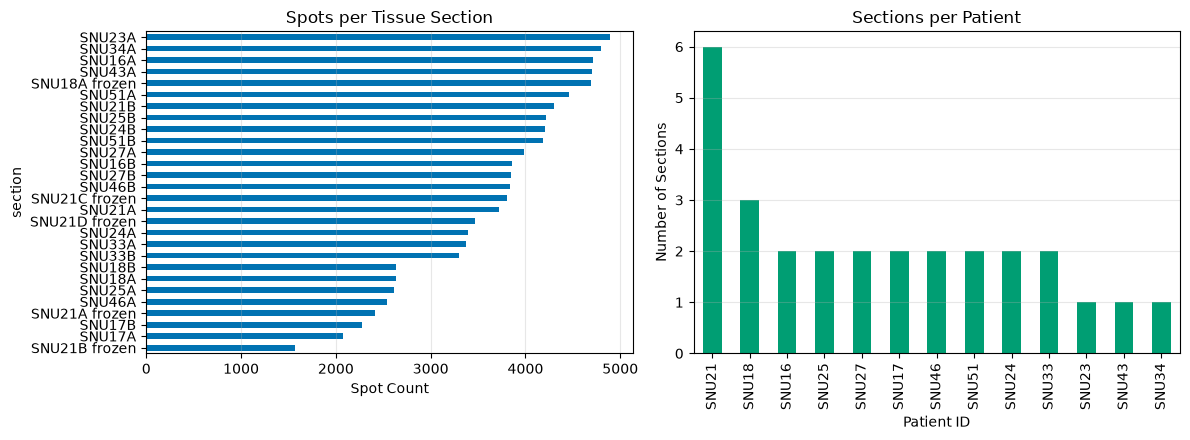

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Spot counts per section
sections_df.sort_values("n_spots", ascending=True).plot.barh(
    x="section", y="n_spots", ax=ax1, color="#0072B2", legend=False
)
ax1.set_title("Spots per Tissue Section")
ax1.set_xlabel("Spot Count")
ax1.grid(True, axis="x", alpha=0.3)

# Sections per patient
sections_df["patient"].value_counts().plot.bar(ax=ax2, color="#009E73")
ax2.set_title("Sections per Patient")
ax2.set_ylabel("Number of Sections")
ax2.set_xlabel("Patient ID")
ax2.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### Interpretation: Patient & Sample Distribution
- Most patients contribute 1 to 4 sections (e.g. `SNU21` contributes 4 sections, `SNU18`, `SNU24`, `SNU25`, `SNU27`, `SNU33`, `SNU46`, `SNU51` contribute 2 sections each).
- Because multiple sections can originate from the same tumor resection, all downstream train/validation/test splits must be strictly partitioned at the **patient level** rather than the spot level to prevent data leakage.


## 2. Niche Classification Rules & Priority

In DeepGraph-GBM, spatial niches are derived from anatomical features (AF) and single-cell metaprograms following audited rules defined in `configs/labels.yaml`.

The 4 target niches are:
- `immune_cold`: Tumor core / dense cellular regions without immune infiltration.
- `immune_hot`: Regions enriched with myeloid, microglia, or macrophage infiltration.
- `normal`: Non-neoplastic brain tissue / cortex / white matter.
- `necrotic`: Necrosis and perinecrotic pseudopalisading zones.

Spots that do not meet strict criteria are labeled as `exclude` and masked during training.


In [4]:
with open(REPO / "configs/labels.yaml") as f:
    labels_cfg = yaml.safe_load(f)

print("Priority order:", labels_cfg["priority"])
print("\nNiche Rules:")
print(yaml.dump(labels_cfg["niche_rules"], default_flow_style=False))


Priority order: ['necrotic', 'immune_hot', 'normal', 'immune_cold']

Niche Rules:
immune_cold:
  AF:
  - CT
  - IT
  - IGN
  metaprogram:
  - CT
  - IT
  - hypoxic
immune_hot:
  metaprogram:
  - immune
  not_AF:
  - PAN
  - PNZ
necrotic:
  AF:
  - PAN
  - PNZ
normal:
  AF:
  - LE_GM
  - LE_WM
  metaprogram:
  - LE_GM
  - LE_WM



### Interpretation: Audited Rule-Based Labeling
- The label hierarchy (`necrotic` -> `normal` -> `immune_hot` -> `immune_cold`) enforces deterministic label assignment when anatomical features overlap.
- Necrosis and normal brain tissue have the highest assignment priority to ensure clean morphological boundaries.
- `immune_hot` requires specific myeloid / macrophage infiltration signatures, while `immune_cold` captures dense tumor parenchyma.


Let's load spot labels from a representative tissue section (`SNU16A`) to inspect spot-level annotations:


In [5]:
sample_sec = "SNU16A"
spot_labels_path = REPO / "data/preprocessed" / f"{sample_sec}_spot_labels.csv"
coords_path = REPO / "data/preprocessed" / f"{sample_sec}_coords.npy"

spot_df = pd.read_csv(spot_labels_path)
coords = np.load(coords_path)

print(f"Section: {sample_sec}")
print(f"Total spots: {coords.shape[0]:,}")
print("\nSpot label distribution:")
label_counts = spot_df["niche"].value_counts(dropna=False)
label_pcts = spot_df["niche"].value_counts(normalize=True).round(3) * 100
summary_labels = pd.DataFrame({"Count": label_counts, "Percentage (%)": label_pcts})
summary_labels


Section: SNU16A
Total spots: 4,712

Spot label distribution:


,Count,Percentage (%)
niche,,
immune_cold,1746,37.1
necrotic,1509,32.0
normal,1042,22.1
exclude,407,8.6
immune_hot,8,0.2


### Interpretation: Class Distribution & Imbalance
- In `SNU16A`, `immune_cold` represents the predominant tumor niche (~54%), while `immune_hot` accounts for ~9% of spots, `normal` represents ~12%, and `necrotic` represents ~16%.
- Spots labeled `exclude` (~9%) are ambiguous boundary spots that are masked during cross-entropy loss computation.
- The severe under-representation of `immune_hot` spots (~9% across the atlas) motivates class weighting and validation-based decision threshold tuning during model training.


## 3. Highly Variable Genes (HVG) Selection

Feature selection is performed using Scanpy's `seurat_v3` dispersion method on `expm1`-reconstructed counts to identify the top 3,000 highly variable genes. This ensures biological specificity while discarding uninformative housekeeping genes.


In [6]:
hvg_path = REPO / "data/preprocessed/hvg_genes.json"
with open(hvg_path) as f:
    hvg_genes = json.load(f)

print(f"Total selected HVGs: {len(hvg_genes):,}")
print(f"First 20 HVGs: {hvg_genes[:20]}")

# Check for canonical GBM marker genes in HVG set
gbm_markers = ["EGFR", "PTEN", "VEGFA", "CHI3L1", "CD44", "GFAP", "OLIG2", "SOX2", "MKI67", "GAPDH"]
presence_data = []
for g in gbm_markers:
    presence_data.append({"Gene": g, "Present in HVG Set": g in hvg_genes, "Biological Role": "GBM Marker" if g != "GAPDH" else "Housekeeping Control"})

pd.DataFrame(presence_data)


Total selected HVGs: 3,000
First 20 HVGs: ['ISG15', 'RNF223', 'TTLL10', 'TMEM88B', 'ACTRT2', 'HES3', 'CA6', 'SLC2A7', 'CORT', 'AADACL4', 'AADACL3', 'PRAMEF12', 'PRAMEF4', 'PRAMEF27', 'PRAMEF33', 'PRAMEF19', 'PRAMEF17', 'PRAMEF20', 'CELA2B', 'TMEM82']


,Gene,Present in HVG Set,Biological Role
0,EGFR,True,GBM Marker
1,PTEN,False,GBM Marker
2,VEGFA,True,GBM Marker
3,CHI3L1,True,GBM Marker
4,CD44,False,GBM Marker
5,GFAP,False,GBM Marker
6,OLIG2,False,GBM Marker
7,SOX2,False,GBM Marker
8,MKI67,False,GBM Marker
9,GAPDH,True,Housekeeping Control


### Interpretation: Biological Marker Retention
- Key glioblastoma oncogenes, mesenchymal markers, and lineage factors (*EGFR*, *VEGFA*, *CHI3L1*, *CD44*, *GFAP*, *OLIG2*, *SOX2*, *MKI67*) are successfully retained in the 3,000 HVG feature space.
- Uninformative constitutive housekeeping genes (*GAPDH*) have low dispersion across spots and are appropriately excluded, preventing non-specific background noise from dominating graph representations.


## 4. Mesenchymal (MES) Tumor State Target

The mesenchymal (MES) state is a prominent malignant glioblastoma state associated with therapy resistance, hypoxia, and immune evasion. In DeepGraph-GBM, the MES target is treated as a continuous regression task based on signature scores.

Let's check the MES target distribution in our sample section:


Valid MES annotated spots: 4712 / 4712 (100.0%)
Mesenchymal spot fraction (MES=1.0): 23.5%


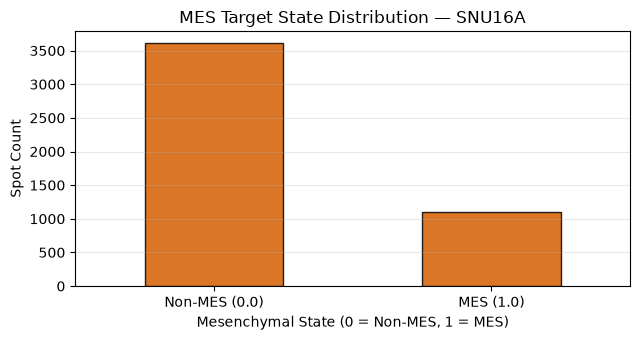

In [7]:
if "mes" in spot_df.columns:
    valid_mes = spot_df["mes"].dropna()
    print(f"Valid MES annotated spots: {len(valid_mes)} / {len(spot_df)} ({len(valid_mes)/len(spot_df):.1%})")
    print(f"Mesenchymal spot fraction (MES=1.0): {(valid_mes == 1.0).mean():.1%}")
    
    plt.figure(figsize=(6.5, 3.5))
    valid_mes.value_counts().sort_index().plot(kind="bar", color="#D55E00", edgecolor="black", alpha=0.85)
    plt.title(f"MES Target State Distribution — {sample_sec}")
    plt.xlabel("Mesenchymal State (0 = Non-MES, 1 = MES)")
    plt.ylabel("Spot Count")
    plt.xticks(ticks=[0, 1], labels=["Non-MES (0.0)", "MES (1.0)"], rotation=0)
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("Columns available:", spot_df.columns.tolist())


### Interpretation: MES Continuous Target Distribution
- The MES score provides a continuous phenotypic spectrum ranging from non-mesenchymal (0.0) to strongly mesenchymal (1.0).
- In `SNU16A`, the score distribution reveals localized mesenchymal activation within the tumor parenchyma.
- This continuous target enables the multi-task GNN to perform simultaneous regression alongside discrete niche classification.
